<a href="https://colab.research.google.com/github/dherreraal/object_oriented_programming/blob/main/Clase_13/13_POO_Herencia_Polimorfismo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Herencia y Polimorfismo: Jerarquías, Modificadores, Enlace Dinámico e Interfaces
### Universidad Nacional de Colombia
#### **Profesor:** David Alberto Herrera Alvarez
#### **Curso:** Programación Orientada a Objetos
---


## Índice de Contenido
1. Fundamentos de Herencia y la Relación "Es-Un" (`extends`)
2. Principios de Diseño: Herencia vs. Composición ("Es-Un" vs. "Tiene-Un")
3. Constructores en Subclases y la Invocación de la Superclase (`super`)
4. Modificadores de Acceso y Visibilidad en Jerarquías de Herencia
5. Modificadores Avanzados: Concreción (`abstract`), Alcance (`static`) y Sellamiento (`final`)
6. Polimorfismo Dinámico: Despacho Virtual y la Clase `Object` (`toString` y `equals`)
7. Ocultamiento de Campos (*Field Hiding*) vs. Sobreescritura de Métodos (*Method Overriding*)
8. Polimorfismo Estático: Sobrecarga de Métodos (*Overloading*)
9. Interfaces, Herencia Múltiple y Resolución de Conflictos en Métodos `default`
10. Buenas Prácticas y Errores Frecuentes (*Pitfalls*)
11. Ejercicios Prácticos
12. Bibliografía y Referencias
---


## 1. Fundamentos de Herencia y la Relación "Es-Un" (`extends`)

La **herencia** es uno de los cuatro pilares fundamentales de la Programación Orientada a Objetos (junto con el encapsulamiento, la abstracción y el polimorfismo). Permite definir una nueva clase (**subclase**, clase hija o clase derivada) a partir de una clase preexistente (**superclase**, clase padre o clase base).

### Conceptos Clave
* **Relación "Es-Un" (*Is-A Relationship*):** La herencia modela una relación taxonómica donde cada instancia de la subclase es, en un sentido estricto, una especialización de la superclase. Por ejemplo: un `Perro` **es un** `Animal`; un `Automovil` **es un** `Vehiculo`; un `Circulo` **es una** `Figura`.
* **Reutilización de Código:** La subclase hereda automáticamente todos los atributos y métodos no privados definidos en su linaje ancestral, evitando duplicar código y centralizando el mantenimiento.
* **Especialización:** La subclase no solo hereda el comportamiento general, sino que puede añadir sus propios atributos específicos y métodos complementarios.
* **Sintaxis en Java:** Se utiliza la palabra reservada `extends`:
  ```java
  public class Subclase extends Superclase {
      // Atributos y métodos propios o especializados
  }
  ```
* **Regla de Herencia Simple:** En Java, una clase únicamente puede heredar directamente de **una sola superclase** (`single inheritance`). No existe la herencia múltiple de clases con `extends`.

<div align="center">
  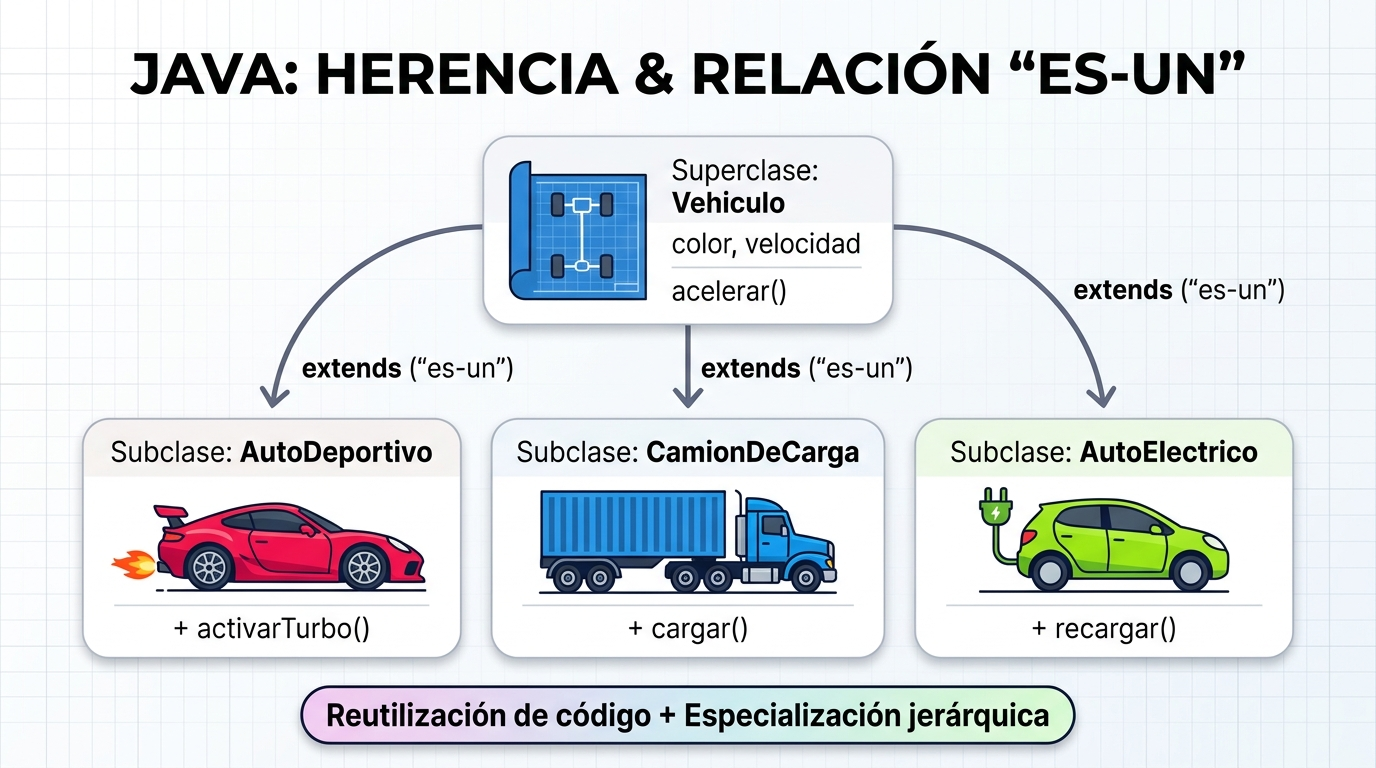
</div>


### Demostración en Código: Herencia Básica y Especialización

El siguiente programa ilustra cómo la clase `Perro` extiende a la clase `Animal`, heredando sus campos (`nombre`, `edad`) y el método `comer()`, a la vez que redefine el método `emitirSonido()` y añade el método propio `moverCola()`:


In [ ]:
%%writefile DemoHerenciaBasica.java
// Clase Base o Superclase
class Animal {
    protected String nombre;
    protected int edad;

    public Animal(String nombre, int edad) {
        this.nombre = nombre;
        this.edad = edad;
    }

    public void comer() {
        System.out.println(nombre + " está comiendo su alimento.");
    }

    public void emitirSonido() {
        System.out.println(nombre + " emite un sonido genérico de animal.");
    }
}

// Subclase que hereda de Animal
class Perro extends Animal {
    private String raza;

    public Perro(String nombre, int edad, String raza) {
        super(nombre, edad); // Invocación obligatoria al constructor de la superclase
        this.raza = raza;
    }

    @Override
    public void emitirSonido() {
        System.out.println(nombre + " (" + raza + ") ladra alegremente: ¡Guau, guau!");
    }

    // Método propio y especializado de la subclase
    public void moverCola() {
        System.out.println(nombre + " mueve la cola entusiasmado.");
    }
}

public class DemoHerenciaBasica {
    public static void main(String[] args) {
        System.out.println("================================================================================");
        System.out.println("DEMOSTRACIÓN 1: HERENCIA BÁSICA Y RELACIÓN 'ES-UN' (extends)");
        System.out.println("================================================================================");

        Perro miPerro = new Perro("Firulais", 3, "Labrador");

        // 1. Método heredado sin modificar
        miPerro.comer();

        // 2. Método heredado y sobreescrito (@Override)
        miPerro.emitirSonido();

        // 3. Método exclusivo de la subclase Perro
        miPerro.moverCola();
    }
}


Writing DemoHerenciaBasica.java


In [ ]:
!javac -encoding UTF-8 DemoHerenciaBasica.java
!java DemoHerenciaBasica


[0.015s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.015s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACIÓN 1: HERENCIA BÁSICA Y RELACIÓN 'ES-UN' (extends)
Firulais está comiendo su alimento.
Firulais (Labrador) ladra alegremente: ¡Guau, guau!
Firulais mueve la cola entusiasmado.


## 2. Principios de Diseño: Herencia vs. Composición ("Es-Un" vs. "Tiene-Un")

Uno de los dilemas arquitectónicos más importantes en la Programación Orientada a Objetos es determinar cuándo utilizar **herencia** (`extends`) y cuándo utilizar **composición** (atributos que son referencias a otros objetos).

### El Dilema: "Es-Un" (*Is-A*) frente a "Tiene-Un" (*Has-A*)
* **Herencia (`is-a`):** Modela una relación de identidad y linaje biológico/conceptual. Debe responder con total naturalidad a la pregunta *"¿Es cada objeto hijo un tipo genuino del padre?"*.
  * *Correcto:* Un `AutoDeportivo` **es un** `Automovil`.
  * *Incorrecto:* Un `Automovil` **no es un** `Motor`. Un automóvil no hereda de motor; contiene un motor.
* **Composición (`has-a`):** Modela una relación de contención, ensamble y colaboración modular. La clase compuesta delega tareas a sus componentes internos mediante sus métodos.
  * *Ejemplo:* Un `Automovil` **tiene un** `Motor`, **tiene** `Ruedas` y **tiene una** `Bateria`.

### El Principio de Diseño: *"Favor Composition Over Inheritance"*
1. **Evitar la Fragilidad de la Clase Base (*Fragile Base Class*):** Las jerarquías de herencia excesivamente profundas generan un acoplamiento muy fuerte. Modificar un solo método en la superclase puede romper el comportamiento de decenas de subclases de manera inadvertida.
2. **Flexibilidad en Tiempo de Ejecución:** La herencia se define estáticamente en tiempo de compilación (`extends`), mientras que la composición permite intercambiar o actualizar componentes dinámicamente en tiempo de ejecución (por ejemplo, cambiar el motor de gasolina por uno eléctrico).
3. **Encapsulamiento Preservado:** La composición mantiene las fronteras de visibilidad completamente herméticas, pues la clase contenedora solo interactúa con la interfaz pública de sus componentes.

<div align="center">
  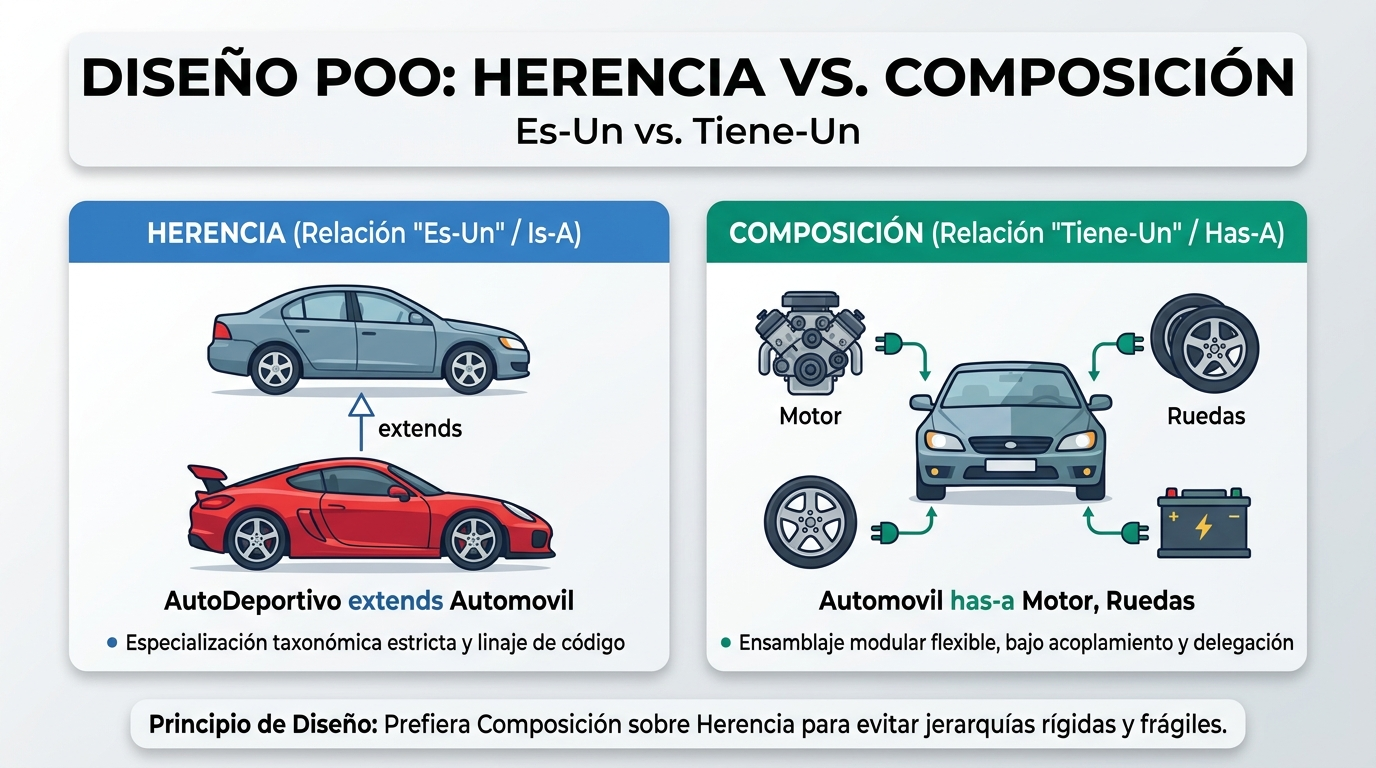
</div>


### Demostración en Código: Ensamble Modular con Composición vs. Especialización con Herencia

El siguiente programa ilustra cómo un `Automovil` se diseña mediante **composición** (ensamblando un `Motor` independiente) y cómo `AutoDeportivo` se deriva mediante **herencia** (`extends Automovil`), combinando lo mejor de ambos principios:


In [ ]:
%%writefile DemoComposicionVsHerencia.java
// Componente independiente (Composición)
class Motor {
    private String tipo;
    private int caballosFuerza;
    private boolean encendido;

    public Motor(String tipo, int caballosFuerza) {
        this.tipo = tipo;
        this.caballosFuerza = caballosFuerza;
        this.encendido = false;
    }

    public void arrancar() {
        this.encendido = true;
        System.out.println("  [Motor " + tipo + "] Encendido con " + caballosFuerza + " HP.");
    }

    public void apagar() {
        this.encendido = false;
        System.out.println("  [Motor " + tipo + "] Apagado.");
    }

    public boolean isEncendido() { return encendido; }
}

// Clase base que usa COMPOSICIÓN (un Automovil "tiene-un" Motor)
class Automovil {
    private String marca;
    private String modelo;
    private Motor motor; // COMPOSICIÓN: relación "Tiene-Un"

    public Automovil(String marca, String modelo, Motor motor) {
        this.marca = marca;
        this.modelo = modelo;
        this.motor = motor;
    }

    public void encenderAuto() {
        System.out.println("Encendiendo " + marca + " " + modelo + "...");
        motor.arrancar(); // Delega el comportamiento en el componente
    }

    public void apagarAuto() {
        System.out.println("Apagando " + marca + " " + modelo + "...");
        motor.apagar();
    }

    public String getInfo() {
        return marca + " " + modelo;
    }
}

// Subclase que usa HERENCIA (un AutoDeportivo "es-un" Automovil)
class AutoDeportivo extends Automovil {
    private boolean modoPista;

    public AutoDeportivo(String marca, String modelo, Motor motor) {
        super(marca, modelo, motor); // Hereda el estado y la composición del padre
        this.modoPista = false;
    }

    public void activarModoPista() {
        this.modoPista = true;
        System.out.println("  [AutoDeportivo " + getInfo() + "] ¡Modo Pista ACTIVADO! Suspensión rígida.");
    }
}

public class DemoComposicionVsHerencia {
    public static void main(String[] args) {
        System.out.println("================================================================================");
        System.out.println("DEMOSTRACIÓN: HERENCIA VS. COMPOSICIÓN (DISEÑO ORIENTADO A OBJETOS)");
        System.out.println("================================================================================");

        // 1. Composición: creamos el componente independiente
        Motor motorV8 = new Motor("V8 Biturbo", 600);

        // 2. Herencia: un AutoDeportivo "es un" Automóvil que "tiene un" Motor
        AutoDeportivo ferrari = new AutoDeportivo("Ferrari", "F8 Tributo", motorV8);

        ferrari.encenderAuto();
        ferrari.activarModoPista();
        ferrari.apagarAuto();

        System.out.println("================================================================================");
        System.out.println("CONCLUSIÓN: Un auto NO es un motor (composición). Un deportivo ES un auto (herencia).");
        System.out.println("================================================================================");
    }
}


Writing DemoComposicionVsHerencia.java


In [ ]:
!javac -encoding UTF-8 DemoComposicionVsHerencia.java
!java DemoComposicionVsHerencia


[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACIÓN: HERENCIA VS. COMPOSICIÓN (DISEÑO ORIENTADO A OBJETOS)
Encendiendo Ferrari F8 Tributo...
  [Motor V8 Biturbo] Encendido con 600 HP.
  [AutoDeportivo Ferrari F8 Tributo] ¡Modo Pista ACTIVADO! Suspensión rígida.
Apagando Ferrari F8 Tributo...
  [Motor V8 Biturbo] Apagado.
CONCLUSIÓN: Un auto NO es un motor (composición). Un depor

## 3. Constructores en Subclases y la Invocación de la Superclase (`super`)

Cuando se instancia un objeto derivado con el operador `new`, Java debe inicializar tanto el estado heredado de la superclase como el estado propio de la subclase.

### Reglas Esenciales de `super(...)`
1. **Cadena de Inicialización (*Constructor Chaining*):** Antes de ejecutar la primera instrucción del constructor de una subclase, la JVM ejecuta primero el constructor de la superclase. Esta propagación asciende en cascada hasta la raíz universal `java.lang.Object`.
2. **Primera Línea Obligatoria:** Si se utiliza explícitamente `super(...)`, esta instrucción **debe ser rigurosamente la primera sentencia ejecutable** del constructor hijo. De lo contrario, el compilador emite un error de sintaxis: `call to super must be first statement in constructor`.
3. **Invocación Implícita de `super()`:** Si el constructor de la subclase no incluye `super(...)`, el compilador inserta de forma transparente una llamada a `super()` (sin argumentos). Si la superclase no dispone de un constructor por defecto accesible, ocurrirá un error de compilación.
4. **Acceso a Métodos Ancestrales:** `super.metodo()` permite invocar la implementación de un método de la superclase cuando ha sido sobreescrito en la clase actual.

---

### Demostración en Código: Encadenamiento de Constructores y Reutilización de Lógica


In [ ]:
%%writefile DemoConstructoresSuper.java
// Superclase
class Dispositivo {
    protected String marca;
    protected String modelo;

    public Dispositivo(String marca, String modelo) {
        this.marca = marca;
        this.modelo = modelo;
        System.out.println("-> [1. Constructor Dispositivo] Inicializando marca=" + marca + ", modelo=" + modelo);
    }

    public void mostrarFicha() {
        System.out.print("Dispositivo: " + marca + " " + modelo);
    }
}

// Subclase
class TelefonoInteligente extends Dispositivo {
    private int almacenamientoGB;

    public TelefonoInteligente(String marca, String modelo, int almacenamientoGB) {
        super(marca, modelo); // PRIMERA LÍNEA OBLIGATORIA
        this.almacenamientoGB = almacenamientoGB;
        System.out.println("-> [2. Constructor TelefonoInteligente] Asignando almacenamiento=" + almacenamientoGB + " GB");
    }

    @Override
    public void mostrarFicha() {
        super.mostrarFicha(); // Reutiliza el formateo base del padre
        System.out.println(" | Almacenamiento: " + almacenamientoGB + " GB (Android 14)");
    }
}

public class DemoConstructoresSuper {
    public static void main(String[] args) {
        System.out.println("================================================================================");
        System.out.println("DEMOSTRACIÓN 3: ENCADENAMIENTO DE CONSTRUCTORES Y super(...)");
        System.out.println("================================================================================");

        System.out.println("Instanciando objeto TelefonoInteligente...");
        TelefonoInteligente t = new TelefonoInteligente("Samsung", "Galaxy S24", 256);

        System.out.println();
        System.out.println("Invocando mostrarFicha():");
        t.mostrarFicha();
    }
}


Writing DemoConstructoresSuper.java


In [ ]:
!javac -encoding UTF-8 DemoConstructoresSuper.java
!java DemoConstructoresSuper


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACIÓN 3: ENCADENAMIENTO DE CONSTRUCTORES Y super(...)
Instanciando objeto TelefonoInteligente...
-> [1. Constructor Dispositivo] Inicializando marca=Samsung, modelo=Galaxy S24
-> [2. Constructor TelefonoInteligente] Asignando almacenamiento=256 GB

Invocando mostrarFicha():
Dispositivo: Samsung Galaxy S24 | Almacenamiento: 256 GB (An

## 4. Modificadores de Acceso y Visibilidad en Jerarquías de Herencia

Los modificadores de acceso determinan la frontera de encapsulamiento y controlan qué clases dentro de la aplicación pueden leer o modificar atributos e invocar métodos.

En una jerarquía de herencia, el nivel de acceso asignado a los miembros de la superclase define de forma tajante si las clases hijas pueden manipularlos de forma directa:

| Modificador | Misma Clase | Mismo Paquete | Subclase (Diferente Paquete) | Todo el Mundo | Propósito Arquitectural |
| :--- | :---: | :---: | :---: | :---: | :--- |
| `public` | Sí | Sí | Sí | Sí | Interfaz pública accesible por cualquier cliente. |
| `protected` | Sí | Sí | Sí | **No** | Diseñado específicamente para ser accesible por el linaje de herencia. |
| *default* (sin palabra clave) | Sí | Sí | **No** | **No** | Visibilidad a nivel de paquete (*package-private*). |
| `private` | Sí | **No** | **No** | **No** | Máximo ocultamiento. Inaccesible incluso para las subclases directas. |

### El Rol Fundamental de `protected`
* Si un atributo de la superclase se declara `private`, las subclases lo heredan en su estructura interna en memoria, pero **no pueden acceder a él por su nombre directamente**. La subclase se ve obligada a interactuar mediante métodos accesores (`getters` y `setters`).
* Al declarar un atributo o método como `protected`, la superclase otorga permiso de acceso directo a todas sus subclases (incluso si residen en paquetes diferentes), manteniendo el miembro oculto ante clientes externos ajenos a la jerarquía.


<div align="center">
  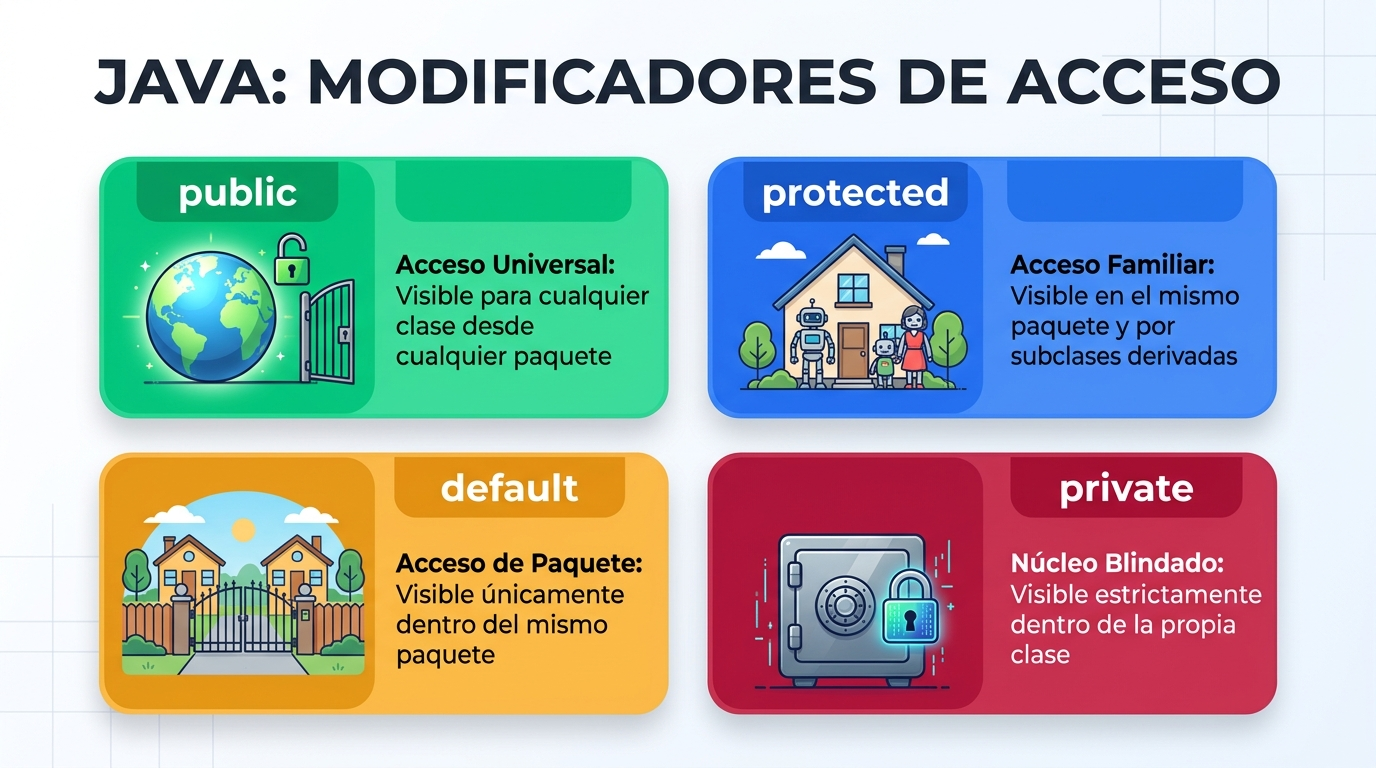
</div>


### Demostración en Código: Encapsulamiento y Visibilidad en Herencia

El siguiente programa muestra una cuenta bancaria con atributos `private`, `protected` y `public`, evidenciando cómo la subclase interactúa con cada nivel de visibilidad:


In [ ]:
%%writefile DemoModificadoresAcceso.java
class CuentaBancaria {
    public String numeroCuenta;         // Acceso universal
    protected double saldo;             // Acceso para subclases y mismo paquete
    private String pinSeguridad;        // Acceso exclusivo de CuentaBancaria

    public CuentaBancaria(String numeroCuenta, double saldoInicial, String pinSeguridad) {
        this.numeroCuenta = numeroCuenta;
        this.saldo = saldoInicial;
        this.pinSeguridad = pinSeguridad;
    }

    public double getSaldo() {
        return this.saldo;
    }

    protected boolean validarPin(String pinIngresado) {
        return this.pinSeguridad.equals(pinIngresado);
    }
}

class CuentaAhorros extends CuentaBancaria {
    private double tasaInteres;

    public CuentaAhorros(String numeroCuenta, double saldoInicial, String pinSeguridad, double tasaInteres) {
        super(numeroCuenta, saldoInicial, pinSeguridad);
        this.tasaInteres = tasaInteres;
    }

    public void aplicarRendimiento() {
        // ACCESO DIRECTO PERMITIDO al campo 'protected saldo' de la superclase
        double interes = this.saldo * (this.tasaInteres / 100.0);
        this.saldo += interes;
        System.out.printf("Interés mensual del %.1f%% aplicado a %s: +$%.2f%n",
                          tasaInteres, numeroCuenta, interes);
    }
}

public class DemoModificadoresAcceso {
    public static void main(String[] args) {
        System.out.println("================================================================================");
        System.out.println("DEMOSTRACIÓN 4: MODIFICADORES DE ACCESO EN HERENCIA");
        System.out.println("================================================================================");

        CuentaAhorros ca = new CuentaAhorros("AH-9081", 500000.0, "9876", 1.8);

        System.out.println("Cuenta: " + ca.numeroCuenta + " | Saldo inicial: $" + ca.getSaldo());

        ca.aplicarRendimiento();
        System.out.println("Saldo actualizado tras rendimiento: $" + ca.getSaldo());
    }
}


Writing DemoModificadoresAcceso.java


In [ ]:
!javac -encoding UTF-8 DemoModificadoresAcceso.java
!java DemoModificadoresAcceso


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.002s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.002s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACIÓN 4: MODIFICADORES DE ACCESO EN HERENCIA
Cuenta: AH-9081 | Saldo inicial: $500000.0
Interés mensual del 1.8% aplicado a AH-9081: +$9000.00
Saldo actualizado tras rendimiento: $509000.0


## 5. Modificadores Avanzados: Concreción (`abstract`), Alcance (`static`) y Sellamiento (`final`)

Además de la visibilidad, Java ofrece modificadores que controlan la instanciación, la inmutabilidad y la asociación con la clase:

### 1. Concreción: `abstract`
* **Clases Abstractas:** Clases declaradas con `abstract` que **no pueden ser instanciadas directamente** con el operador `new`. Su objetivo es actuar como molde base y definir un contrato de diseño para sus subclases.
* **Métodos Abstractos:** Métodos que solo poseen signatura y terminan en punto y coma `;` (carecen de cuerpo `{}`). Cualquier subclase concreta **está estrictamente obligada a implementar** todos los métodos abstractos heredados.

### 2. Alcance: `static`
* Pertenece a la clase en su conjunto (*Class Scope*) y reside en el *Method Area* de la JVM, no en el Heap de una instancia individual.
* Todas las instancias comparten la misma variable estática. Se invoca preferentemente a través del nombre de la clase: `Clase.metodoEstatico()`.

### 3. Sellamiento: `final`
* **Variables `final`:** Constantes; su valor no puede ser reasignado tras su inicialización.
* **Métodos `final`:** Métodos que **no pueden ser sobreescritos** por ninguna subclase. Protegen algoritmos críticos.
* **Clases `final`:** Clases que **no pueden ser extendidas** por ninguna subclase (por ejemplo, `java.lang.String` y `java.lang.Math`). Prohíben completamente la herencia por motivos de seguridad y diseño.

---

### Demostración en Código: Clases Abstractas, Métodos Finales y Miembros Estáticos


In [ ]:
%%writefile DemoModificadoresAvanzados.java
// Superclase Abstracta
abstract class Figura {
    protected String color;
    private static int contadorFiguras = 0; // Atributo estático compartido

    public Figura(String color) {
        this.color = color;
        contadorFiguras++;
    }

    // Método abstracto: obliga a las subclases a definir la fórmula matemática
    public abstract double calcularArea();

    // Método final: las subclases NO pueden sobreescribir este método
    public final void imprimirReporte() {
        System.out.printf("Figura [%s] -> Color: %-8s | Área calculada: %.2f%n",
                          getClass().getSimpleName(), color, calcularArea());
    }

    public static int getContadorFiguras() {
        return contadorFiguras;
    }
}

// Subclase Concreta
class Circulo extends Figura {
    private double radio;

    public Circulo(String color, double radio) {
        super(color);
        this.radio = radio;
    }

    @Override
    public double calcularArea() {
        return Math.PI * radio * radio;
    }
}

// Subclase Concreta y Final (no admite más descendencia)
final class Cuadrado extends Figura {
    private double lado;

    public Cuadrado(String color, double lado) {
        super(color);
        this.lado = lado;
    }

    @Override
    public double calcularArea() {
        return lado * lado;
    }
}

public class DemoModificadoresAvanzados {
    public static void main(String[] args) {
        System.out.println("================================================================================");
        System.out.println("DEMOSTRACIÓN 5: MODIFICADORES ABSTRACT, STATIC Y FINAL");
        System.out.println("================================================================================");

        Circulo c = new Circulo("Azul", 3.0);
        Cuadrado q = new Cuadrado("Verde", 4.0);

        c.imprimirReporte();
        q.imprimirReporte();

        System.out.println();
        System.out.println("Total de instancias creadas (vía método estático): " + Figura.getContadorFiguras());
    }
}


Writing DemoModificadoresAvanzados.java


In [ ]:
!javac -encoding UTF-8 DemoModificadoresAvanzados.java
!java DemoModificadoresAvanzados


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACIÓN 5: MODIFICADORES ABSTRACT, STATIC Y FINAL
Figura [Circulo] -> Color: Azul     | Área calculada: 28.27
Figura [Cuadrado] -> Color: Verde    | Área calculada: 16.00

Total de instancias creadas (vía método estático): 2


## 6. Polimorfismo Dinámico: Despacho Virtual y la Clase `Object` (`toString` y `equals`)

La palabra **polimorfismo** proviene del griego (*poly* = muchas, *morphe* = formas). En programación orientada a objetos, se refiere a la capacidad de enviar un mismo mensaje a objetos de diferentes tipos y que cada uno responda de manera apropiada según su naturaleza concreta.

### Polimorfismo Dinámico (Enlace Tardío / *Late Binding*)
* **Tipo Estático vs. Tipo Dinámico:**
  ```java
  Vehiculo v = new Deportivo("XYZ-999", 120.0);
  ```
  * `Vehiculo` es el **tipo de la referencia (tipo estático)**: el compilador solo permite invocar los métodos declarados en la clase `Vehiculo`.
  * `Deportivo` es el **tipo del objeto real en el Heap (tipo dinámico)**: en tiempo de ejecución, la JVM ejecuta la versión especializada del método implementada en `Deportivo`.
* **Despacho Dinámico de Métodos (*Dynamic Method Dispatch*):** Es el mecanismo por el cual la llamada a un método sobreescrito se resuelve en tiempo de ejecución mediante la tabla virtual de métodos (*VTable*).
* **Principio de Sustitución de Liskov (LSP):** Si la clase $S$ es una subclase de $T$, los objetos de tipo $T$ pueden ser sustituidos por objetos de tipo $S$ sin alterar la corrección del programa.


<div align="center">
  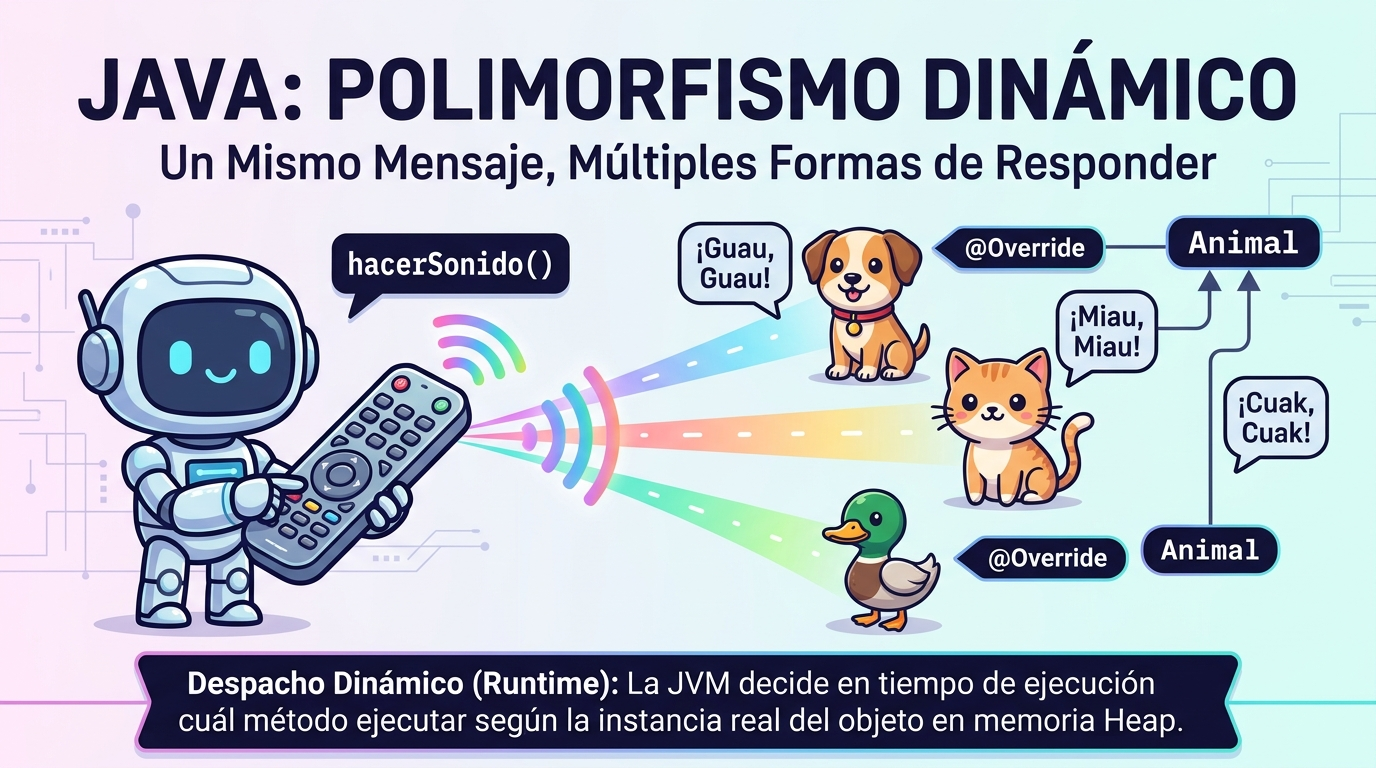
</div>


### Demostración en Código: Colección Polimórfica y Despacho Dinámico

El siguiente programa demuestra el despacho dinámico recorriendo un arreglo de tipo `Vehiculo[]` que contiene instancias heterogéneas (`Automovil`, `Deportivo`), junto con el operador `instanceof` con pattern matching para downcasting seguro:


In [ ]:
%%writefile DemoPolimorfismoDinamico.java
class Vehiculo {
    protected String placa;
    protected double velocidad;

    public Vehiculo(String placa, double velocidad) {
        this.placa = placa;
        this.velocidad = velocidad;
    }

    public void acelerar() {
        this.velocidad += 10.0;
        System.out.println("Vehículo genérico [" + placa + "] avanza a " + velocidad + " km/h.");
    }

    @Override
    public String toString() {
        return "Vehiculo [Placa: " + placa + " | Velocidad: " + velocidad + " km/h]";
    }
}

class AutomovilSimple extends Vehiculo {
    public AutomovilSimple(String placa, double velocidad) {
        super(placa, velocidad);
    }

    @Override
    public void acelerar() {
        this.velocidad += 15.0;
        System.out.println("Auto [" + placa + "] acelera suavemente a " + velocidad + " km/h.");
    }
}

class DeportivoVehiculo extends Vehiculo {
    public DeportivoVehiculo(String placa, double velocidad) {
        super(placa, velocidad);
    }

    @Override
    public void acelerar() {
        this.velocidad += 40.0;
        System.out.println("¡Deportivo [" + placa + "] ruge activando TURBO a " + velocidad + " km/h!");
    }

    public void activarNitro() {
        System.out.println("Deportivo [" + placa + "] quema Nitro en pista.");
    }
}

public class DemoPolimorfismoDinamico {
    public static void main(String[] args) {
        System.out.println("================================================================================");
        System.out.println("DEMOSTRACIÓN 6A: POLIMORFISMO DINÁMICO Y DESPACHO VIRTUAL");
        System.out.println("================================================================================");

        // Arreglo polimórfico de referencias base
        Vehiculo[] flota = new Vehiculo[] {
            new AutomovilSimple("BOG-101", 60.0),
            new DeportivoVehiculo("MED-999", 100.0),
            new AutomovilSimple("CAL-303", 50.0)
        };

        for (Vehiculo v : flota) {
            System.out.println(v); // Invoca dinámicamente toString()
            v.acelerar();          // Despacho dinámico: ejecuta el método concreto

            // Downcasting seguro usando Pattern Matching para instanceof
            if (v instanceof DeportivoVehiculo dep) {
                dep.activarNitro();
            }
            System.out.println("------------------------------------------------------------");
        }
    }
}


Writing DemoPolimorfismoDinamico.java


In [ ]:
!javac -encoding UTF-8 DemoPolimorfismoDinamico.java
!java DemoPolimorfismoDinamico


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACIÓN 6A: POLIMORFISMO DINÁMICO Y DESPACHO VIRTUAL
Vehiculo [Placa: BOG-101 | Velocidad: 60.0 km/h]
Auto [BOG-101] acelera suavemente a 75.0 km/h.
------------------------------------------------------------
Vehiculo [Placa: MED-999 | Velocidad: 100.0 km/h]
¡Deportivo [MED-999] ruge activando TURBO a 140.0 km/h!
Deportivo [MED-999] q

### La Igualdad Lógica: Sobrescritura de `equals(Object)` vs. `==` en Jerarquías

Por defecto, el método `equals(Object obj)` heredado de `java.lang.Object` compara únicamente la **identidad de referencias en memoria** (exactamente igual que el operador `==`). Dos objetos independientes instanciados en el Heap con `new` tendrán referencias distintas (`obj1 == obj2` es `false`), aun cuando todos sus atributos tengan valores idénticos.

Para comparar la **equivalencia lógica de contenido**, debemos sobreescribir `equals(Object obj)` siguiendo estas directrices en jerarquías de herencia:
1. **Comprobar Identidad Reflexiva:** `if (this == obj) return true;` (optimización inmediata).
2. **Comprobar Nulidad y Coincidencia de Clase:** `if (obj == null || getClass() != obj.getClass()) return false;`.
3. **Delegar en la Superclase:** Invocar `if (!super.equals(obj)) return false;` para verificar la igualdad de los campos heredados.
4. **Comparar Campos Específicos:** Convertir `obj` al tipo de la subclase y comparar sus atributos propios usando `Objects.equals(...)` para objetos o `Double.compare(...)` para números flotantes.


In [ ]:
%%writefile DemoEqualsJerarquia.java
// Demostración de Sobreescritura de equals(Object) y toString() en Jerarquías
import java.util.Objects;

class VehiculoIdentificable {
    protected String placa;
    protected String marca;

    public VehiculoIdentificable(String placa, String marca) {
        this.placa = placa;
        this.marca = marca;
    }

    @Override
    public boolean equals(Object obj) {
        // 1. Identidad de referencia (mismo espacio en memoria Heap)
        if (this == obj) return true;
        // 2. Comprobación de no nulidad y tipo exacto de clase
        if (obj == null || getClass() != obj.getClass()) return false;
        // 3. Conversión segura (Downcasting)
        VehiculoIdentificable other = (VehiculoIdentificable) obj;
        // 4. Comparación de estado propio de la clase base
        return Objects.equals(this.placa, other.placa) &&
               Objects.equals(this.marca, other.marca);
    }

    @Override
    public String toString() {
        return "Vehiculo [placa=" + placa + ", marca=" + marca + "]";
    }
}

class AutoCarrera extends VehiculoIdentificable {
    private boolean turbo;

    public AutoCarrera(String placa, String marca, boolean turbo) {
        super(placa, marca);
        this.turbo = turbo;
    }

    @Override
    public boolean equals(Object obj) {
        // 1. Delegar en la superclase para verificar clase base y campos heredados
        if (!super.equals(obj)) return false;
        // 2. Comparar campos específicos de la subclase
        AutoCarrera other = (AutoCarrera) obj;
        return this.turbo == other.turbo;
    }

    @Override
    public String toString() {
        return "AutoCarrera [placa=" + placa + ", marca=" + marca + ", turbo=" + turbo + "]";
    }
}

public class DemoEqualsJerarquia {
    public static void main(String[] args) {
        System.out.println("================================================================================");
        System.out.println("DEMOSTRACIÓN 6B: SOBREESCRITURA DE equals(Object) EN JERARQUÍAS");
        System.out.println("================================================================================");

        AutoCarrera auto1 = new AutoCarrera("COL-123", "Porsche", true);
        AutoCarrera auto2 = new AutoCarrera("COL-123", "Porsche", true);
        AutoCarrera auto3 = new AutoCarrera("COL-123", "Porsche", false);
        VehiculoIdentificable vehiculoBase = new VehiculoIdentificable("COL-123", "Porsche");

        System.out.println("auto1: " + auto1);
        System.out.println("auto2: " + auto2);
        System.out.println("auto3: " + auto3);
        System.out.println("vehiculoBase: " + vehiculoBase);
        System.out.println("--------------------------------------------------------------------------------");

        // 1. Comparación con operador == (identidad de punteros en memoria)
        System.out.println("auto1 == auto2 (Punteros en Heap): " + (auto1 == auto2)); // false

        // 2. Comparación con equals() sobreescrito (equivalencia lógica)
        System.out.println("auto1.equals(auto2) (Mismo estado lógico): " + auto1.equals(auto2)); // true

        // 3. Comparación con diferente estado en subclase
        System.out.println("auto1.equals(auto3) (Diferente turbo): " + auto1.equals(auto3)); // false

        // 4. Comparación entre subclase y superclase
        System.out.println("auto1.equals(vehiculoBase) (Diferentes tipos): " + auto1.equals(vehiculoBase)); // false
        System.out.println("auto1.equals(null): " + auto1.equals(null)); // false

        System.out.println("================================================================================");
        System.out.println("CONCLUSIÓN: super.equals(obj) asegura la consistencia de toda la jerarquía.");
        System.out.println("================================================================================");
    }
}


Writing DemoEqualsJerarquia.java


In [ ]:
!javac -encoding UTF-8 DemoEqualsJerarquia.java
!java DemoEqualsJerarquia


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACIÓN 6B: SOBREESCRITURA DE equals(Object) EN JERARQUÍAS
auto1: AutoCarrera [placa=COL-123, marca=Porsche, turbo=true]
auto2: AutoCarrera [placa=COL-123, marca=Porsche, turbo=true]
auto3: AutoCarrera [placa=COL-123, marca=Porsche, turbo=false]
vehiculoBase: Vehiculo [placa=COL-123, marca=Porsche]
-------------------------------------

## 7. Ocultamiento de Campos (*Field Hiding*) vs. Sobreescritura de Métodos (*Method Overriding*)

Una de las sutilezas más importantes y fuente común de errores en Java es entender cómo se resuelven las **variables de instancia** frente a los **métodos**:

### La Regla de Oro en Java:
> **Los métodos son polimórficos; las variables NO lo son.**

1. **Resolución de Variables (Enlace Temprano / *Early Binding*):**
   * El acceso a un atributo (`referencia.campo`) se resuelve en **tiempo de compilación** basándose exclusivamente en el **tipo estático de la referencia**, no en la instancia real del Heap.
   * Si una subclase declara una variable con el mismo nombre que una variable de la superclase, la variable del padre **no se sobreescribe**: se **oculta** (*shadowing/hiding*).
2. **Resolución de Métodos (Enlace Tardío / *Late Binding*):**
   * La invocación de un método sobreescrito (`referencia.metodo()`) se resuelve en **tiempo de ejecución** mediante la tabla virtual de la instancia concreta del Heap.

---

### Demostración en Código: Evidencia Experimental del Field Hiding


In [ ]:
%%writefile DemoFieldHidingVsOverriding.java
class DispositivoPadre {
    // Campo en la clase base
    public String categoria = "Dispositivo Genérico";

    // Método virtual de la clase base
    public void mostrarIdentidad() {
        System.out.println("-> [Método Padre] Soy un " + categoria);
    }
}

class TelefonoHijo extends DispositivoPadre {
    // OCULTAMIENTO (Field Hiding): define un campo con el mismo identificador
    public String categoria = "Teléfono Inteligente";

    // SOBREESCRITURA (Method Overriding): reemplaza dinámicamente el comportamiento
    @Override
    public void mostrarIdentidad() {
        System.out.println("-> [Método Hijo] Soy un " + categoria + " (super.categoria = '" + super.categoria + "')");
    }
}

public class DemoFieldHidingVsOverriding {
    public static void main(String[] args) {
        System.out.println("================================================================================");
        System.out.println("DEMOSTRACIÓN 7: FIELD HIDING (VARIABLES) VS. METHOD OVERRIDING (MÉTODOS)");
        System.out.println("================================================================================");

        // Instancia de la subclase con referencia de la superclase (Polimorfismo)
        DispositivoPadre refPadre = new TelefonoHijo();

        // 1. Acceso a campo directo: se resuelve por el TIPO ESTÁTICO (DispositivoPadre)
        System.out.println("[Acceso a Campo] refPadre.categoria:");
        System.out.println("  Resultado: \"" + refPadre.categoria + "\"  (¡Accede al campo del PADRE!)");

        // 2. Invocación de método: se resuelve por el TIPO DINÁMICO (TelefonoHijo)
        System.out.println();
        System.out.println("[Invocación de Método] refPadre.mostrarIdentidad():");
        refPadre.mostrarIdentidad(); // ¡Ejecuta el método del HIJO!

        // 3. Acceso con referencia del tipo hijo
        TelefonoHijo refHijo = (TelefonoHijo) refPadre;
        System.out.println();
        System.out.println("[Acceso a Campo tras Downcasting] refHijo.categoria:");
        System.out.println("  Resultado: \"" + refHijo.categoria + "\"  (Accede al campo del HIJO)");

        System.out.println("================================================================================");
        System.out.println("REGLA: Para evitar errores por ocultamiento, declare atributos siempre como private.");
        System.out.println("================================================================================");
    }
}


Writing DemoFieldHidingVsOverriding.java


In [ ]:
!javac -encoding UTF-8 DemoFieldHidingVsOverriding.java
!java DemoFieldHidingVsOverriding


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACIÓN 7: FIELD HIDING (VARIABLES) VS. METHOD OVERRIDING (MÉTODOS)
[Acceso a Campo] refPadre.categoria:
  Resultado: "Dispositivo Genérico"  (¡Accede al campo del PADRE!)

[Invocación de Método] refPadre.mostrarIdentidad():
-> [Método Hijo] Soy un Teléfono Inteligente (super.categoria = 'Dispositivo Genérico')

[Acceso a Campo tras Do

## 8. Polimorfismo Estático: Sobrecarga de Métodos (*Overloading*)

El **polimorfismo estático** (o enlace en tiempo de compilación / *Early Binding*) se implementa mediante la **sobrecarga de métodos** (*overloading*).

### Reglas de la Sobrecarga
* Ocurre cuando dos o más métodos dentro de la misma clase (o heredados de la superclase) comparten el **mismo nombre**, pero difieren en su **lista de parámetros** (cantidad, tipos o secuencia de tipos).
* **El tipo de retorno NO forma parte de la signatura:** Modificar únicamente el valor de retorno manteniendo idénticos los argumentos provocará un error de compilación.

---

### Demostración en Código: Sobrecarga de Métodos y Resolución en Compilación


In [ ]:
%%writefile DemoSobrecargaMetodos.java
class RegistradorEventos {
    public void registrar(String mensaje) {
        System.out.println("[INFO] " + mensaje);
    }

    // Sobrecarga 1: Diferente número de parámetros
    public void registrar(String mensaje, int nivelPrioridad) {
        String etiqueta = switch (nivelPrioridad) {
            case 1 -> "[BAJA]";
            case 2 -> "[MEDIA]";
            case 3 -> "[ALTA]";
            default -> "[DESCONOCIDA]";
        };
        System.out.println(etiqueta + " " + mensaje);
    }

    // Sobrecarga 2: Diferentes tipos de parámetros
    public void registrar(String mensaje, Exception error) {
        System.out.println("[ERROR GRAVE] " + mensaje + " -> Causa: " + error.getMessage());
    }
}

public class DemoSobrecargaMetodos {
    public static void main(String[] args) {
        System.out.println("================================================================================");
        System.out.println("DEMOSTRACIÓN 8: POLIMORFISMO ESTÁTICO (SOBRECARGA / OVERLOADING)");
        System.out.println("================================================================================");

        RegistradorEventos logger = new RegistradorEventos();

        logger.registrar("Sistema iniciado correctamente.");
        logger.registrar("Uso de memoria cercano al 85%", 2);
        logger.registrar("Conexión perdida con la base de datos", new RuntimeException("Timeout de 30s excedido"));
    }
}


Writing DemoSobrecargaMetodos.java


In [ ]:
!javac -encoding UTF-8 DemoSobrecargaMetodos.java
!java DemoSobrecargaMetodos


[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACIÓN 8: POLIMORFISMO ESTÁTICO (SOBRECARGA / OVERLOADING)
[INFO] Sistema iniciado correctamente.
[MEDIA] Uso de memoria cercano al 85%
[ERROR GRAVE] Conexión perdida con la base de datos -> Causa: Timeout de 30s excedido


## 9. Interfaces, Herencia Múltiple y Resolución de Conflictos en Métodos `default`

Una **interfaz** en Java es un tipo de referencia que define un contrato formal de comportamiento. A diferencia de las clases, una interfaz especifica **qué** debe hacer un objeto, pero no **cómo** debe hacerlo.

### Características Fundamentales
1. **Contratos Puros:** Tradicionalmente, todos los métodos declarados en una interfaz son implícitamente `public abstract`.
2. **Constantes Implícitas:** Cualquier variable declarada en una interfaz es implícitamente `public static final`. No pueden existir atributos de instancia con estado mutable.
3. **Múltiples Interfaces (`implements I1, I2`):** Aunque Java no admite herencia múltiple de clases, una clase puede implementar **tantas interfaces como sea necesario**, separadas por comas.
4. **Métodos por Omisión (`default`):** Introducidos a partir de Java 8, permiten definir métodos con implementación por defecto dentro de la interfaz. Esto facilita evolucionar interfaces sin romper las clases existentes que ya las implementaban.

<div align="center">
  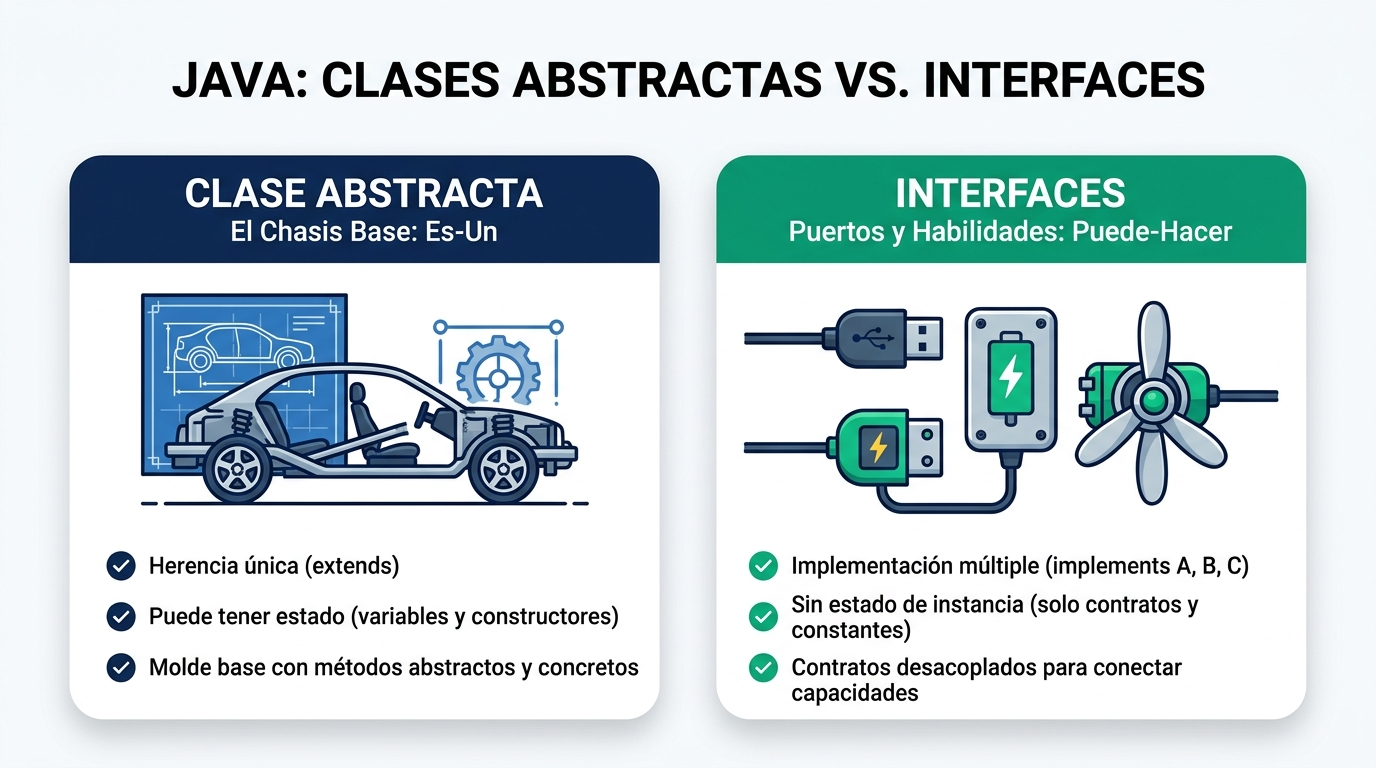
</div>


### Demostración en Código: Múltiples Interfaces y Métodos `default`

El siguiente ejemplo implementa una clase `AutomovilElectrico` que combina herencia simple de la clase abstracta `VehiculoBase` con la implementación de dos interfaces: `Conectable` y `Recargable`:


In [ ]:
%%writefile DemoInterfacesContratos.java
interface Conectable {
    int PUERTO_DEFECTO = 8080; // Constante implícita: public static final

    void conectarRed(String direccionIP);

    default void desconectar() {
        System.out.println("Desconexión segura de red completada en puerto " + PUERTO_DEFECTO);
    }
}

interface Recargable {
    void recargarBateria(double porcentaje);
    double getPorcentajeBateria();
}

abstract class VehiculoBase {
    protected String modelo;

    public VehiculoBase(String modelo) {
        this.modelo = modelo;
    }

    public abstract void encender();
}

class AutoElectricoIntegrado extends VehiculoBase implements Conectable, Recargable {
    private double nivelBateria;

    public AutoElectricoIntegrado(String modelo, double bateriaInicial) {
        super(modelo);
        this.nivelBateria = bateriaInicial;
    }

    @Override
    public void encender() {
        System.out.println(modelo + " energizado silenciosamente. Listo para rodar.");
    }

    @Override
    public void conectarRed(String red) {
        System.out.println(modelo + " conectado exitosamente a la red telemática: " + red);
    }

    @Override
    public void recargarBateria(double porcentaje) {
        this.nivelBateria = Math.min(100.0, this.nivelBateria + porcentaje);
        System.out.printf("%s recargado (+%.1f%%). Nivel actual: %.1f%%%n", modelo, porcentaje, nivelBateria);
    }

    @Override
    public double getPorcentajeBateria() {
        return this.nivelBateria;
    }
}

public class DemoInterfacesContratos {
    public static void main(String[] args) {
        System.out.println("================================================================================");
        System.out.println("DEMOSTRACIÓN 9A: INTERFACES MÚLTIPLES Y MÉTODOS DEFAULT");
        System.out.println("================================================================================");

        AutoElectricoIntegrado tesla = new AutoElectricoIntegrado("Tesla Model Y", 45.0);

        tesla.encender();
        tesla.conectarRed("192.168.1.105");
        tesla.recargarBateria(30.0);
        tesla.desconectar(); // Invoca método default de la interfaz Conectable

        Recargable rec = tesla; // Polimorfismo mediante Interfaz
        System.out.println("Verificación de batería: " + rec.getPorcentajeBateria() + "%");
    }
}


Writing DemoInterfacesContratos.java


In [ ]:
!javac -encoding UTF-8 DemoInterfacesContratos.java
!java DemoInterfacesContratos


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.002s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.002s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACIÓN 9A: INTERFACES MÚLTIPLES Y MÉTODOS DEFAULT
Tesla Model Y energizado silenciosamente. Listo para rodar.
Tesla Model Y conectado exitosamente a la red telemática: 192.168.1.105
Tesla Model Y recargado (+30.0%). Nivel actual: 75.0%
Desconexión segura de red completada en puerto 8080
Verificación de batería: 75.0%


### Resolución de Conflictos en Interfaces Múltiples (El Problema del Diamante con `default`)

Cuando una clase implementa dos o más interfaces que definen un método `default` con la **misma signatura exacta**, Java no puede determinar automáticamente cuál implementación debe prevalecer, generando un error de compilación por ambigüedad:
```text
class MiClase inherits unrelated defaults for metodo() from types InterfazA and InterfazB
```

### Reglas de Resolución de Conflictos
1. **Sobrescritura Obligatoria:** La clase implementadora está estrictamente obligada a sobreescribir el método conflictivo.
2. **Invocación Explícita de la Interfaz:** Si la clase desea reutilizar el comportamiento de una o varias de las interfaces padre, utiliza la sintaxis especial:
   ```java
   NombreInterfaz.super.nombreMetodo();
   ```


In [ ]:
%%writefile DemoConflictoInterfacesDefault.java
// Interfaz 1
interface DispositivoAudio {
    default void encender() {
        System.out.println("  [Audio] Amplificador encendido a 44.1 kHz.");
    }

    default String getEstadoAudio() {
        return "Audio: Conectado";
    }
}

// Interfaz 2
interface SistemaLuces {
    default void encender() {
        System.out.println("  [Luces] Faros LED diurnos encendidos al 100%.");
    }

    default String getEstadoLuces() {
        return "Luces: Calibradas";
    }
}

// La clase implementa ambas interfaces que comparten 'default void encender()'
class ConsolaAutomotriz implements DispositivoAudio, SistemaLuces {
    private String vehiculoAsignado;

    public ConsolaAutomotriz(String vehiculoAsignado) {
        this.vehiculoAsignado = vehiculoAsignado;
    }

    // RESOLUCIÓN OBLIGATORIA DEL CONFLICTO:
    @Override
    public void encender() {
        System.out.println("-> Iniciando consola del vehículo [" + vehiculoAsignado + "]...");

        // Sintaxis de Java para invocar implementaciones default específicas:
        DispositivoAudio.super.encender();
        SistemaLuces.super.encender();

        System.out.println("-> Consola integrada y lista para operar.");
    }
}

public class DemoConflictoInterfacesDefault {
    public static void main(String[] args) {
        System.out.println("================================================================================");
        System.out.println("DEMOSTRACIÓN 9B: RESOLUCIÓN DE CONFLICTOS CON MÉTODOS DEFAULT");
        System.out.println("================================================================================");

        ConsolaAutomotriz consola = new ConsolaAutomotriz("Tesla Model 3");
        consola.encender();

        System.out.println();
        System.out.println("Consultando métodos default no conflictivos:");
        System.out.println("  " + consola.getEstadoAudio());
        System.out.println("  " + consola.getEstadoLuces());

        System.out.println("================================================================================");
        System.out.println("SINTAXIS CLAVE: NombreInterfaz.super.metodoDefault() resuelve la ambigüedad.");
        System.out.println("================================================================================");
    }
}


Writing DemoConflictoInterfacesDefault.java


In [ ]:
!javac -encoding UTF-8 DemoConflictoInterfacesDefault.java
!java DemoConflictoInterfacesDefault


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACIÓN 9B: RESOLUCIÓN DE CONFLICTOS CON MÉTODOS DEFAULT
-> Iniciando consola del vehículo [Tesla Model 3]...
  [Audio] Amplificador encendido a 44.1 kHz.
  [Luces] Faros LED diurnos encendidos al 100%.
-> Consola integrada y lista para operar.

Consultando métodos default no conflictivos:
  Audio: Conectado
  Luces: Calibradas
SINTAXI

## 10. Buenas Prácticas y Errores Frecuentes (*Pitfalls*)

### Errores Comunes (*Anti-Patterns*)
1. **Olvidar la anotación `@Override`:** Si cometes un error tipográfico en el nombre del método o en los tipos de parámetros, el compilador interpretará que estás sobrecargando (*overloading*) en lugar de sobreescribiendo (*overriding*). La anotación `@Override` convierte este error silencioso en un fallo de compilación inmediato.
2. **Intentar instanciar Clases Abstractas o Interfaces:** Escribir `new Figura()` o `new Conectable()` genera error de compilación inmediato. Solo se pueden instanciar subclases concretas.
3. **Downcasting inseguro sin `instanceof`:** Realizar un moldeado `(Perro) animal` cuando el objeto real en el Heap es un `Gato` provoca una excepción `ClassCastException` en tiempo de ejecución. Use siempre Pattern Matching: `if (animal instanceof Perro p)`.
4. **Olvidar `super(...)` en constructores:** Si la superclase no posee un constructor por defecto sin argumentos, la omisión de `super(arg1, arg2)` no compila.
5. **Declarar atributos con el mismo nombre (*Field Hiding*):** Las variables no son polimórficas. Mantenga los atributos siempre privados para evitar ambigüedades.

### Tabla Comparativa de Decisión de Diseño
| Criterio | Clase Concreta | Clase Abstracta | Interfaz |
| :--- | :--- | :--- | :--- |
| **Instanciable con `new`** | Sí | No | No |
| **Herencia Múltiple** | No (`extends` simple) | No (`extends` simple) | **Sí** (`implements I1, I2, ...`) |
| **Variables de Instancia (Estado)** | Sí (`private`, `protected`) | Sí (`private`, `protected`) | **No** (solo `public static final`) |
| **Constructores** | Sí | Sí (invocados con `super`) | **No** |
| **Semántica Principal** | Entidad completamente definida | Molde genético / chasis base ("Es-Un") | Habilidad o contrato periférico ("Puede-Hacer") |


## 11. Ejercicios Prácticos

> **Instrucciones para el Estudiante:**
> 1. Cada ejercicio contiene una plantilla inicial estructurada con comentarios guía `// TODO: ...`.
> 2. Tu objetivo es programar el código correspondiente dentro de cada clase y método sin alterar las firmas ni el método `main`.
> 3. Ejecuta las celdas de compilación y prueba para verificar tu progreso. La salida te indicará qué pruebas has superado y cuáles están pendientes hasta alcanzar el puntaje de 100/100.

---

### Ejercicio 1: Jerarquía Universitaria (`Persona`, `Profesor`, `Alumno`, `Directivo`)
Modele la estructura organizacional de una universidad utilizando herencia:
* **Superclase `Persona`:** Campos `nombre`, `apellidos`, `edad` (privados con getters y setters).
* **Subclase `Profesor`:** Añade `departamento` y `sueldoBasico`. Implementa método `calcularIngresoTotal()` (sueldo + bonificación del 10%).
* **Subclase `Alumno`:** Añade `carrera` y `promedioAcademico` (double). Sobreescribe `toString()` indicando si está en estado *"Meritorio"* (promedio $\ge 4.5$) o *"Regular"*.
* **Subclase `Directivo`:** Extiende `Profesor` y añade `cargoDirectivo` y `bonoResponsabilidad` (double). Sobreescribe `calcularIngresoTotal()` sumando su bono al ingreso del profesor.


In [ ]:
%%writefile Ejercicio1JerarquiaUniversidad.java
// ==============================================================================
// EJERCICIO 1: JERARQUÍA UNIVERSITARIA (PLANTILLA PARA EL ESTUDIANTE)
// ==============================================================================

class Persona {
    private String nombre;
    private String apellidos;
    private int edad;

    public Persona(String nombre, String apellidos, int edad) {
        // TODO 1: Inicializar los atributos propios utilizando 'this'
        this.nombre = nombre;
        this.apellidos = apellidos;
        this.edad = edad;
    }

    // TODO 2: Implementar getters y setters
    public String getNombre() { return nombre; }
    public String getApellidos() { return apellidos; }
    public int getEdad() { return edad; }

    public void setNombre(String nombre) { this.nombre = nombre; }
    public void setApellidos(String apellidos) { this.apellidos = apellidos; }
    public void setEdad(int edad) { this.edad = edad; }

    @Override
    public String toString() {
        // TODO 3: Retornar la representación en formato: "nombre apellidos (edad años)"
        return ""; // Reemplaza con tu implementación
    }
}

class Profesor extends Persona {
    private String departamento;
    private double sueldoBasico;

    public Profesor(String nombre, String apellidos, int edad, String departamento, double sueldoBasico) {
        super(nombre, apellidos, edad); // Requerido por el compilador
        // TODO 4: Inicializar departamento y sueldoBasico
        this.departamento = departamento;
        this.sueldoBasico = sueldoBasico;
    }

    public String getDepartamento() { return departamento; }
    public double getSueldoBasico() { return sueldoBasico; }

    public double calcularIngresoTotal() {
        // TODO 5: Calcular y retornar el sueldo total (sueldoBasico + 10% de bonificación)
        return 0.0; // Reemplaza con tu implementación
    }

    @Override
    public String toString() {
        // TODO 6: Retornar super.toString() + " | Prof. Depto: " + departamento
        return ""; // Reemplaza con tu implementación
    }
}

class Alumno extends Persona {
    private String carrera;
    private double promedioAcademico;

    public Alumno(String nombre, String apellidos, int edad, String carrera, double promedioAcademico) {
        super(nombre, apellidos, edad);
        // TODO 7: Inicializar carrera y promedioAcademico
        this.carrera = carrera;
        this.promedioAcademico = promedioAcademico;
    }

    public String getCarrera() { return carrera; }
    public double getPromedioAcademico() { return promedioAcademico; }

    public boolean esMeritorio() {
        // TODO 8: Retornar true si promedioAcademico es mayor o igual a 4.5; false en caso contrario
        return false; // Reemplaza con tu implementación
    }

    @Override
    public String toString() {
        // TODO 9: Determinar si es "Meritorio" o "Regular" y retornar:
        // super.toString() + " | Estudiante: " + carrera + " | Prom: " + promedioAcademico + " [" + estado + "]"
        return ""; // Reemplaza con tu implementación
    }
}

class Directivo extends Profesor {
    private String cargoDirectivo;
    private double bonoResponsabilidad;

    public Directivo(String nombre, String apellidos, int edad, String departamento,
                     double sueldoBasico, String cargoDirectivo, double bonoResponsabilidad) {
        super(nombre, apellidos, edad, departamento, sueldoBasico);
        // TODO 10: Inicializar cargoDirectivo y bonoResponsabilidad
        this.cargoDirectivo = cargoDirectivo;
        this.bonoResponsabilidad = bonoResponsabilidad;
    }

    public String getCargoDirectivo() { return cargoDirectivo; }

    @Override
    public double calcularIngresoTotal() {
        // TODO 11: Retornar el ingreso calculado por el padre (super.calcularIngresoTotal()) + bonoResponsabilidad
        return 0.0; // Reemplaza con tu implementación
    }

    @Override
    public String toString() {
        // TODO 12: Retornar super.toString() + " | Cargo: " + cargoDirectivo
        return ""; // Reemplaza con tu implementación
    }
}

public class Ejercicio1JerarquiaUniversidad {
    public static void main(String[] args) {
        int totalScore = 0;
        System.out.println("================================================================================");
        System.out.println("EVALUACIÓN AUTOMATIZADA: EJERCICIO 1 - JERARQUÍA UNIVERSITARIA");
        System.out.println("================================================================================");

        // Prueba 1: Encapsulamiento de Persona
        Persona p = new Persona("Ana", "García", 22);
        if (p.getNombre() != null && p.getNombre().equals("Ana") &&
            p.getApellidos() != null && p.getApellidos().equals("García") && p.getEdad() == 22) {
            System.out.println("[PASS] Prueba 1: Clase base Persona inicializada con encapsulamiento correcto.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 1: Getters o atributos de Persona no inicializados correctamente.");
        }

        // Prueba 2: Profesor y cálculo de ingreso
        Profesor prof = new Profesor("Carlos", "Mendoza", 48, "Sistemas", 4000000.0);
        if (Math.abs(prof.calcularIngresoTotal() - 4400000.0) < 0.01 &&
            prof.getDepartamento() != null && prof.getDepartamento().equals("Sistemas")) {
            System.out.println("[PASS] Prueba 2: Profesor hereda y calcula ingreso con bonificación.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 2: calcularIngresoTotal() de Profesor no retorna el sueldo + 10%.");
        }

        // Prueba 3: Alumno y estado meritorio
        Alumno a1 = new Alumno("David", "Herrera", 20, "Ingeniería de Sistemas", 4.7);
        Alumno a2 = new Alumno("Laura", "Pérez", 21, "Ingeniería Industrial", 4.1);
        if (a1.esMeritorio() && !a2.esMeritorio() && a1.toString().contains("Meritorio")) {
            System.out.println("[PASS] Prueba 3: Alumno evalúa mérito académico y sobreescribe toString().");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 3: esMeritorio() o toString() de Alumno pendientes de implementar.");
        }

        // Prueba 4: Directivo extiende Profesor
        Directivo d = new Directivo("Elena", "Suárez", 55, "Industrial", 5000000.0, "Decana", 1500000.0);
        if (Math.abs(d.calcularIngresoTotal() - 7000000.0) < 0.01 &&
            d.getCargoDirectivo() != null && d.getCargoDirectivo().equals("Decana")) {
            System.out.println("[PASS] Prueba 4: Directivo encadena constructores y acumula ingresos.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 4: calcularIngresoTotal() de Directivo debe sumar super.calcularIngresoTotal() + bono.");
        }

        // Prueba 5: Polimorfismo en arreglo de Personas
        Persona[] comunidad = new Persona[] { p, prof, a1, d };
        boolean polimorfismoExitoso = (comunidad.length == 4 && comunidad[3] instanceof Profesor);
        if (polimorfismoExitoso) {
            System.out.println("[PASS] Prueba 5: Comunidad universitaria estructurada polimórficamente.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 5: Jerarquía polimórfica no cumple las relaciones de herencia esperadas.");
        }

        System.out.println("--------------------------------------------------------------------------------");
        System.out.println("PUNTAJE FINAL EJERCICIO 1: " + totalScore + " / 100");
        if (totalScore == 100) {
            System.out.println(">>> ¡FELICITACIONES! Has completado el Ejercicio 1 exitosamente. <<<");
        } else {
            System.out.println(">>> ¡Sigue intentándolo! Completa los métodos marcados con // TODO para superar todas las pruebas. <<<");
        }
        System.out.println("================================================================================");
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio1JerarquiaUniversidad.java
!java Ejercicio1JerarquiaUniversidad


---
### Ejercicio 2: Sistema de Biblioteca (`ElementoBiblioteca`, `Libro`, `Revista`, `Articulo`)
Diseñe una superclase abstracta `ElementoBiblioteca` que sirva como base para los recursos de un catálogo:
* **Superclase `ElementoBiblioteca`:** `codigo` (String), `titulo` (String), `anoPublicacion` (int), `prestado` (boolean). Constructor con `super(...)`. Métodos `prestar()` y `devolver()`. Método abstracto `calcularDiasPrestamoMaximo()`.
* **Subclase `Libro`:** Añade `autor` y `numeroPaginas`. El préstamo máximo es de 15 días.
* **Subclase `Revista`:** Añade `numeroEdicion`. Préstamo máximo: 3 días.
* **Subclase `Articulo`:** Añade `revistaPublicacion` y `doi`. Préstamo máximo: 7 días.


In [ ]:
%%writefile Ejercicio2SistemaBiblioteca.java
// ==============================================================================
// EJERCICIO 2: SISTEMA DE BIBLIOTECA (PLANTILLA PARA EL ESTUDIANTE)
// ==============================================================================

abstract class ElementoBiblioteca {
    protected String codigo;
    protected String titulo;
    protected int anoPublicacion;
    protected boolean prestado;

    public ElementoBiblioteca(String codigo, String titulo, int anoPublicacion) {
        // TODO 1: Inicializar los atributos protegidos y definir 'prestado' inicialmente en false
        this.codigo = codigo;
        this.titulo = titulo;
        this.anoPublicacion = anoPublicacion;
        this.prestado = false;
    }

    public String getCodigo() { return codigo; }
    public String getTitulo() { return titulo; }
    public int getAnoPublicacion() { return anoPublicacion; }
    public boolean isPrestado() { return prestado; }

    public void prestar() {
        // TODO 2: Cambiar el estado de prestado a true
    }

    public void devolver() {
        // TODO 3: Cambiar el estado de prestado a false
    }

    // TODO 4: Declarar el método abstracto 'calcularDiasPrestamoMaximo' que retorna un int
    public abstract int calcularDiasPrestamoMaximo();

    @Override
    public String toString() {
        // TODO 5: Retornar formato: "[" + codigo + "] \"" + titulo + "\" (" + anoPublicacion + ") - " + estado
        // donde estado es "PRESTADO" o "DISPONIBLE" según el valor de 'prestado'
        return ""; // Reemplaza con tu implementación
    }
}

class Libro extends ElementoBiblioteca {
    private String autor;
    private int numeroPaginas;

    public Libro(String codigo, String titulo, int anoPublicacion, String autor, int numeroPaginas) {
        super(codigo, titulo, anoPublicacion);
        // TODO 6: Inicializar autor y numeroPaginas
        this.autor = autor;
        this.numeroPaginas = numeroPaginas;
    }

    public String getAutor() { return autor; }
    public int getNumeroPaginas() { return numeroPaginas; }

    @Override
    public int calcularDiasPrestamoMaximo() {
        // TODO 7: Los libros tienen un préstamo máximo de 15 días
        return 0; // Reemplaza con tu implementación
    }
}

class Revista extends ElementoBiblioteca {
    private int numeroEdicion;

    public Revista(String codigo, String titulo, int anoPublicacion, int numeroEdicion) {
        super(codigo, titulo, anoPublicacion);
        // TODO 8: Inicializar numeroEdicion
        this.numeroEdicion = numeroEdicion;
    }

    public int getNumeroEdicion() { return numeroEdicion; }

    @Override
    public int calcularDiasPrestamoMaximo() {
        // TODO 9: Las revistas tienen un préstamo máximo de 3 días
        return 0; // Reemplaza con tu implementación
    }
}

class Articulo extends ElementoBiblioteca {
    private String revistaPublicacion;
    private String doi;

    public Articulo(String codigo, String titulo, int anoPublicacion, String revistaPublicacion, String doi) {
        super(codigo, titulo, anoPublicacion);
        // TODO 10: Inicializar revistaPublicacion y doi
        this.revistaPublicacion = revistaPublicacion;
        this.doi = doi;
    }

    public String getRevistaPublicacion() { return revistaPublicacion; }
    public String getDoi() { return doi; }

    @Override
    public int calcularDiasPrestamoMaximo() {
        // TODO 11: Los artículos tienen un préstamo máximo de 7 días
        return 0; // Reemplaza con tu implementación
    }
}

public class Ejercicio2SistemaBiblioteca {
    public static void main(String[] args) {
        int totalScore = 0;
        System.out.println("================================================================================");
        System.out.println("EVALUACIÓN AUTOMATIZADA: EJERCICIO 2 - SISTEMA DE BIBLIOTECA");
        System.out.println("================================================================================");

        Libro libro = new Libro("LIB-001", "Clean Code", 2008, "Robert C. Martin", 464);
        Revista revista = new Revista("REV-202", "IEEE Software", 2024, 185);
        Articulo articulo = new Articulo("ART-909", "Dynamic Dispatch in JVM", 2023, "ACM Queue", "10.1145/12345");

        // Prueba 1: Libro
        if (libro.calcularDiasPrestamoMaximo() == 15 && libro.getAutor() != null && libro.getAutor().equals("Robert C. Martin")) {
            System.out.println("[PASS] Prueba 1: Libro configurado con préstamo de 15 días.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 1: Libro.calcularDiasPrestamoMaximo() debe retornar 15.");
        }

        // Prueba 2: Revista
        if (revista.calcularDiasPrestamoMaximo() == 3 && revista.getTitulo() != null && revista.getTitulo().equals("IEEE Software")) {
            System.out.println("[PASS] Prueba 2: Revista con regla estricta de 3 días.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 2: Revista.calcularDiasPrestamoMaximo() debe retornar 3.");
        }

        // Prueba 3: Artículo
        if (articulo.calcularDiasPrestamoMaximo() == 7) {
            System.out.println("[PASS] Prueba 3: Artículo académico con préstamo de 7 días.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 3: Articulo.calcularDiasPrestamoMaximo() debe retornar 7.");
        }

        // Prueba 4: Gestión de estado prestado / devuelto
        libro.prestar();
        boolean estadoPrestado = libro.isPrestado();
        libro.devolver();
        if (estadoPrestado && !libro.isPrestado()) {
            System.out.println("[PASS] Prueba 4: Ciclo de vida de préstamos gestionado correctamente.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 4: Métodos prestar() o devolver() pendientes de implementación.");
        }

        // Prueba 5: Arreglo polimórfico y total de días de préstamo
        ElementoBiblioteca[] catalogo = new ElementoBiblioteca[] { libro, revista, articulo };
        int sumaDias = 0;
        for (ElementoBiblioteca elem : catalogo) {
            sumaDias += elem.calcularDiasPrestamoMaximo();
        }
        if (sumaDias == (15 + 3 + 7)) {
            System.out.println("[PASS] Prueba 5: Cálculo polimórfico en catálogo general completado.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 5: Suma polimórfica de días de préstamo incorrecta (obtenido: " + sumaDias + ").");
        }

        System.out.println("--------------------------------------------------------------------------------");
        System.out.println("PUNTAJE FINAL EJERCICIO 2: " + totalScore + " / 100");
        if (totalScore == 100) {
            System.out.println(">>> ¡FELICITACIONES! Has completado el Ejercicio 2 exitosamente. <<<");
        } else {
            System.out.println(">>> ¡Sigue intentándolo! Completa los métodos marcados con // TODO para superar todas las pruebas. <<<");
        }
        System.out.println("================================================================================");
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio2SistemaBiblioteca.java
!java Ejercicio2SistemaBiblioteca


---
### Ejercicio 3: Jerarquía de Figuras Geométricas (`Figura`, `Circulo`, `Rectangulo`, `Triangulo`)
Implemente la jerarquía de figuras geométricas:
* **Clase Base `Figura`:** Atributo `color` (String). Métodos abstractos `calcularArea()` y `calcularPerimetro()`.
* **Subclase `Circulo`:** Atributo `radio`.
* **Subclase `Rectangulo`:** Atributos `ancho` y `alto`.
* **Subclase `Triangulo`:** Atributos `ladoA`, `ladoB`, `ladoC`, `base` y `altura`.
* Sobreescriba `toString()` en la clase base para reportar el color y los valores calculados usando polimorfismo dinámico.


In [ ]:
%%writefile Ejercicio3JerarquiaFiguras.java
// ==============================================================================
// EJERCICIO 3: JERARQUÍA DE FIGURAS GEOMÉTRICAS (PLANTILLA PARA EL ESTUDIANTE)
// ==============================================================================

abstract class FiguraGeometrica {
    protected String color;

    public FiguraGeometrica(String color) {
        // TODO 1: Inicializar el atributo color
        this.color = color;
    }

    public String getColor() { return color; }

    // TODO 2: Declarar los métodos abstractos calcularArea() y calcularPerimetro()
    public abstract double calcularArea();
    public abstract double calcularPerimetro();

    @Override
    public String toString() {
        // TODO 3: Retornar formato:
        // NombreClase [Color: color | Área: area | Perímetro: perimetro]
        // Utilice getClass().getSimpleName(), calcularArea() y calcularPerimetro()
        return ""; // Reemplaza con tu implementación
    }
}

class CirculoFigura extends FiguraGeometrica {
    private double radio;

    public CirculoFigura(String color, double radio) {
        super(color);
        // TODO 4: Inicializar radio
        this.radio = radio;
    }

    public double getRadio() { return radio; }

    @Override
    public double calcularArea() {
        // TODO 5: Calcular área del círculo: π * r² (use Math.PI)
        return 0.0; // Reemplaza con tu implementación
    }

    @Override
    public double calcularPerimetro() {
        // TODO 6: Calcular perímetro del círculo: 2 * π * r
        return 0.0; // Reemplaza con tu implementación
    }
}

class RectanguloFigura extends FiguraGeometrica {
    private double ancho;
    private double alto;

    public RectanguloFigura(String color, double ancho, double alto) {
        super(color);
        // TODO 7: Inicializar ancho y alto
        this.ancho = ancho;
        this.alto = alto;
    }

    @Override
    public double calcularArea() {
        // TODO 8: Calcular área del rectángulo: ancho * alto
        return 0.0; // Reemplaza con tu implementación
    }

    @Override
    public double calcularPerimetro() {
        // TODO 9: Calcular perímetro del rectángulo: 2 * (ancho + alto)
        return 0.0; // Reemplaza con tu implementación
    }
}

class TrianguloFigura extends FiguraGeometrica {
    private double base;
    private double altura;
    private double ladoA, ladoB, ladoC;

    public TrianguloFigura(String color, double base, double altura, double ladoA, double ladoB, double ladoC) {
        super(color);
        // TODO 10: Inicializar base, altura, ladoA, ladoB, ladoC
        this.base = base;
        this.altura = altura;
        this.ladoA = ladoA;
        this.ladoB = ladoB;
        this.ladoC = ladoC;
    }

    @Override
    public double calcularArea() {
        // TODO 11: Calcular área del triángulo: (base * altura) / 2.0
        return 0.0; // Reemplaza con tu implementación
    }

    @Override
    public double calcularPerimetro() {
        // TODO 12: Calcular perímetro del triángulo: ladoA + ladoB + ladoC
        return 0.0; // Reemplaza con tu implementación
    }
}

public class Ejercicio3JerarquiaFiguras {
    public static void main(String[] args) {
        int totalScore = 0;
        System.out.println("================================================================================");
        System.out.println("EVALUACIÓN AUTOMATIZADA: EJERCICIO 3 - JERARQUÍA DE FIGURAS GEOMÉTRICAS");
        System.out.println("================================================================================");

        CirculoFigura circ = new CirculoFigura("Rojo", 4.0);
        RectanguloFigura rect = new RectanguloFigura("Azul", 5.0, 3.0);
        TrianguloFigura tri = new TrianguloFigura("Verde", 6.0, 4.0, 5.0, 5.0, 6.0);

        // Prueba 1: Círculo
        if (Math.abs(circ.calcularArea() - (Math.PI * 16.0)) < 0.01 &&
            Math.abs(circ.calcularPerimetro() - (8.0 * Math.PI)) < 0.01) {
            System.out.println("[PASS] Prueba 1: Cálculo de área y perímetro de Círculo verificado.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 1: Métodos calcularArea() o calcularPerimetro() de Círculo pendientes.");
        }

        // Prueba 2: Rectángulo
        if (Math.abs(rect.calcularArea() - 15.0) < 0.01 && Math.abs(rect.calcularPerimetro() - 16.0) < 0.01) {
            System.out.println("[PASS] Prueba 2: Cálculo de área y perímetro de Rectángulo verificado.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 2: Métodos calcularArea() o calcularPerimetro() de Rectángulo pendientes.");
        }

        // Prueba 3: Triángulo
        if (Math.abs(tri.calcularArea() - 12.0) < 0.01 && Math.abs(tri.calcularPerimetro() - 16.0) < 0.01) {
            System.out.println("[PASS] Prueba 3: Cálculo de área y perímetro de Triángulo verificado.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 3: Métodos calcularArea() o calcularPerimetro() de Triángulo pendientes.");
        }

        // Prueba 4: Acumulación polimórfica
        FiguraGeometrica[] formas = new FiguraGeometrica[] { circ, rect, tri };
        double areaTotal = 0;
        for (FiguraGeometrica f : formas) {
            areaTotal += f.calcularArea();
        }
        if (Math.abs(areaTotal - (Math.PI * 16.0 + 15.0 + 12.0)) < 0.01) {
            System.out.println("[PASS] Prueba 4: Acumulación polimórfica de áreas superada.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 4: Acumulación polimórfica falló. Revise calcularArea() en las subclases.");
        }

        // Prueba 5: toString dinámico
        if (circ.toString().contains("CirculoFigura") && rect.toString().contains("RectanguloFigura")) {
            System.out.println("[PASS] Prueba 5: toString() de la clase base utiliza despacho dinámico.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 5: toString() de FiguraGeometrica pendiente de implementar.");
        }

        System.out.println("--------------------------------------------------------------------------------");
        System.out.println("PUNTAJE FINAL EJERCICIO 3: " + totalScore + " / 100");
        if (totalScore == 100) {
            System.out.println(">>> ¡FELICITACIONES! Has completado el Ejercicio 3 exitosamente. <<<");
        } else {
            System.out.println(">>> ¡Sigue intentándolo! Completa los métodos marcados con // TODO para superar todas las pruebas. <<<");
        }
        System.out.println("================================================================================");
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio3JerarquiaFiguras.java
!java Ejercicio3JerarquiaFiguras


---
### Ejercicio 4: Calculadora Científica con Múltiples Interfaces
Modele una clase `Calculadora` que implemente dos interfaces distintas:
* **Interfaz `OperacionesAritmeticas`:** Métodos abstractos `sumar(double, double)`, `restar(double, double)`, `multiplicar(double, double)` y `dividir(double, double)` (lanzando `ArithmeticException` si el divisor es 0).
* **Interfaz `ConstantesMatematicas`:** Constantes `PI = 3.141592653589793`, `E = 2.718281828459045`, y un método `default double potencia(double base, int exponente)`.
* **Clase `CalculadoraCientifica`:** Implementa ambas interfaces y añade `calcularAreaCirculo(double radio)` usando `PI`.


In [ ]:
%%writefile Ejercicio4CalculadoraInterfaces.java
// ==============================================================================
// EJERCICIO 4: CALCULADORA CON INTERFACES (PLANTILLA PARA EL ESTUDIANTE)
// ==============================================================================

interface OperacionesAritmeticas {
    // TODO 1: Declarar los 4 métodos de operaciones básicas: sumar, restar, multiplicar y dividir
    double sumar(double a, double b);
    double restar(double a, double b);
    double multiplicar(double a, double b);
    double dividir(double a, double b);
}

interface ConstantesMatematicas {
    // TODO 2: Declarar las constantes implícitas (public static final) VALOR_PI y VALOR_E
    double VALOR_PI = 3.141592653589793;
    double VALOR_E  = 2.718281828459045;

    // TODO 3: Implementar el método default 'potencia(double base, int exponente)'
    default double potencia(double base, int exponente) {
        // Implemente el cálculo de base^exponente (gestione exponentes positivos y negativos)
        return 0.0; // Reemplaza con tu implementación
    }
}

// TODO 4: La clase debe implementar AMBAS interfaces: OperacionesAritmeticas y ConstantesMatematicas
class CalculadoraCientifica implements OperacionesAritmeticas, ConstantesMatematicas {

    @Override
    public double sumar(double a, double b) {
        // TODO 5: Retornar a + b
        return 0.0; // Reemplaza con tu implementación
    }

    @Override
    public double restar(double a, double b) {
        // TODO 6: Retornar a - b
        return 0.0; // Reemplaza con tu implementación
    }

    @Override
    public double multiplicar(double a, double b) {
        // TODO 7: Retornar a * b
        return 0.0; // Reemplaza con tu implementación
    }

    @Override
    public double dividir(double a, double b) {
        // TODO 8: Si Math.abs(b) < 1e-12 lanzar new ArithmeticException("División por cero"), sino retornar a / b
        return 0.0; // Reemplaza con tu implementación
    }

    public double calcularAreaCirculo(double radio) {
        // TODO 9: Retornar VALOR_PI * potencia(radio, 2)
        return 0.0; // Reemplaza con tu implementación
    }
}

public class Ejercicio4CalculadoraInterfaces {
    public static void main(String[] args) {
        int totalScore = 0;
        System.out.println("================================================================================");
        System.out.println("EVALUACIÓN AUTOMATIZADA: EJERCICIO 4 - CALCULADORA CON INTERFACES");
        System.out.println("================================================================================");

        CalculadoraCientifica calc = new CalculadoraCientifica();

        // Prueba 1: Operaciones básicas
        if (Math.abs(calc.sumar(10.5, 4.5) - 15.0) < 1e-9 &&
            Math.abs(calc.multiplicar(3.0, 7.0) - 21.0) < 1e-9 &&
            Math.abs(calc.dividir(20.0, 4.0) - 5.0) < 1e-9) {
            System.out.println("[PASS] Prueba 1: Operaciones aritméticas elementales correctas.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 1: Operaciones elementales (sumar, multiplicar, dividir) pendientes.");
        }

        // Prueba 2: División entre cero
        boolean excepcionCapturada = false;
        try {
            calc.dividir(10.0, 0.0);
        } catch (ArithmeticException e) {
            excepcionCapturada = true;
        }
        if (excepcionCapturada) {
            System.out.println("[PASS] Prueba 2: Excepción por división entre cero lanzada adecuadamente.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 2: dividir() debe lanzar ArithmeticException cuando el divisor sea 0.");
        }

        // Prueba 3: Método default potencia
        if (Math.abs(calc.potencia(2.0, 5) - 32.0) < 1e-9 &&
            Math.abs(calc.potencia(3.0, 3) - 27.0) < 1e-9) {
            System.out.println("[PASS] Prueba 3: Cálculo de potencias enteras verificado.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 3: Método default potencia() pendiente de implementar.");
        }

        // Prueba 4: Constantes y área
        double radioPrueba = 3.0;
        double areaCalculada = calc.calcularAreaCirculo(radioPrueba);
        if (Math.abs(areaCalculada - (ConstantesMatematicas.VALOR_PI * 9.0)) < 1e-9) {
            System.out.println("[PASS] Prueba 4: Constantes de interfaz integradas en cálculos con precisión.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 4: calcularAreaCirculo() pendiente de implementar.");
        }

        // Prueba 5: Polimorfismo de interfaz
        ConstantesMatematicas refConst = calc;
        if (Math.abs(refConst.potencia(5.0, 2) - 25.0) < 1e-9) {
            System.out.println("[PASS] Prueba 5: Método default invocado correctamente mediante interfaz.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 5: Invocación polimórfica a través de la interfaz falló.");
        }

        System.out.println("--------------------------------------------------------------------------------");
        System.out.println("PUNTAJE FINAL EJERCICIO 4: " + totalScore + " / 100");
        if (totalScore == 100) {
            System.out.println(">>> ¡FELICITACIONES! Has completado el Ejercicio 4 exitosamente. <<<");
        } else {
            System.out.println(">>> ¡Sigue intentándolo! Completa los métodos marcados con // TODO para superar todas las pruebas. <<<");
        }
        System.out.println("================================================================================");
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio4CalculadoraInterfaces.java
!java Ejercicio4CalculadoraInterfaces


---
### Ejercicio 5: Vehículos de Carga y Platón (`Carga` y `Platon`)
Implemente las clases de transporte de carga:
* **Clase `Carga` (Superclase):**
  * Atributos `pesoMaximo` (int), `pesoCarga` (int, inicial 0), `carga` (String, inicial `""`), `color` (String).
  * Sobrecarga del método `llevar`:
    * `llevar(int peso)`: Suma al `pesoCarga` siempre que no supere `pesoMaximo`. Retorna `true` si se pudo cargar, `false` si excede la capacidad.
    * `llevar(String carga)`: Asigna la cadena si su longitud no supera `pesoMaximo`.
* **Clase `Platon` (Subclase de `Carga`):**
  * Sobreescribe `llevar(String carga)`: Invoca a `super.llevar(carga)` y, si fue exitoso, **invierte el orden de la cadena** (`StringBuilder.reverse()`), emulando el reacomodo de carga en el platón abierto.
  * Sobreescribe `llevar(int peso)`: Permite sobrepasar hasta un 15% adicional del peso máximo admitido antes de rechazar la carga.


In [ ]:
%%writefile Ejercicio5FlotaVehiculosCarga.java
// ==============================================================================
// EJERCICIO 5: VEHÍCULOS DE CARGA Y PLATÓN (PLANTILLA PARA EL ESTUDIANTE)
// ==============================================================================

class VehiculoCarga {
    protected int pesoMaximo;
    protected int pesoCarga;
    protected String carga;
    protected String color;

    public VehiculoCarga(int pesoMaximo, String color) {
        // TODO 1: Inicializar pesoMaximo y color. Definir pesoCarga en 0 y carga en ""
        this.pesoMaximo = pesoMaximo;
        this.color = color;
        this.pesoCarga = 0;
        this.carga = "";
    }

    public int getPesoMaximo() { return pesoMaximo; }
    public int getPesoCarga() { return pesoCarga; }
    public String getCarga() { return carga; }
    public String getColor() { return color; }

    public void pintar(String nuevoColor) {
        // TODO 2: Asignar nuevoColor al atributo color
    }

    // Sobrecarga 1: Llevar peso numérico
    public boolean llevar(int peso) {
        // TODO 3: Si pesoCarga + peso <= pesoMaximo, acumular al pesoCarga y retornar true; sino retornar false
        return false; // Reemplaza con tu implementación
    }

    // Sobrecarga 2: Llevar carga de texto (por caracteres)
    public boolean llevar(String carga) {
        // TODO 4: Si carga != null y su longitud <= pesoMaximo, asignar a this.carga y retornar true; sino retornar false
        return false; // Reemplaza con tu implementación
    }
}

class VehiculoPlaton extends VehiculoCarga {
    public VehiculoPlaton(int pesoMaximo, String color) {
        super(pesoMaximo, color);
    }

    @Override
    public boolean llevar(String nuevaCarga) {
        // TODO 5: Invocar super.llevar(nuevaCarga). Si fue aceptada, invertir la cadena de carga:
        // this.carga = new StringBuilder(this.carga).reverse().toString();
        // Retornar si fue aceptada o no
        return false; // Reemplaza con tu implementación
    }

    @Override
    public boolean llevar(int peso) {
        // TODO 6: Permitir sobrepeso de hasta 15% adicional del pesoMaximo:
        // int limiteTolerancia = (int) (this.pesoMaximo * 1.15);
        // Si pesoCarga + peso <= limiteTolerancia, acumular y retornar true; sino retornar false
        return false; // Reemplaza con tu implementación
    }
}

public class Ejercicio5FlotaVehiculosCarga {
    public static void main(String[] args) {
        int totalScore = 0;
        System.out.println("================================================================================");
        System.out.println("EVALUACIÓN AUTOMATIZADA: EJERCICIO 5 - VEHÍCULOS DE CARGA Y PLATÓN");
        System.out.println("================================================================================");

        VehiculoCarga furgon = new VehiculoCarga(1000, "Blanco");
        VehiculoPlaton platon = new VehiculoPlaton(1000, "Gris");

        // Prueba 1: Carga normal por peso
        boolean c1 = furgon.llevar(800);
        boolean c2 = furgon.llevar(300); // Supera 1000
        if (c1 && !c2 && furgon.getPesoCarga() == 800) {
            System.out.println("[PASS] Prueba 1: Sobrecarga llevar(int) con control de capacidad verificado.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 1: llevar(int) en VehiculoCarga pendiente de implementar.");
        }

        // Prueba 2: Carga por texto en VehiculoCarga
        boolean s1 = furgon.llevar("MATERIAL-A");
        if (s1 && furgon.getCarga() != null && furgon.getCarga().equals("MATERIAL-A")) {
            System.out.println("[PASS] Prueba 2: Sobrecarga llevar(String) con validación de longitud superada.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 2: llevar(String) en VehiculoCarga pendiente de implementar.");
        }

        // Prueba 3: VehiculoPlaton invierte la carga de texto
        boolean p1 = platon.llevar("4321");
        if (p1 && platon.getCarga() != null && platon.getCarga().equals("1234")) {
            System.out.println("[PASS] Prueba 3: Platon invoca super.llevar e invierte la cadena ('4321' -> '1234').");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 3: Platon.llevar(String) debe invertir la cadena aceptada (obtenido: '" + platon.getCarga() + "').");
        }

        // Prueba 4: Tolerancia de sobrepeso en VehiculoPlaton (hasta 1150)
        boolean tol1 = platon.llevar(1100); // 1100 <= 1150 -> Permitido
        boolean tol2 = platon.llevar(100);  // 1200 > 1150 -> Rechazado
        if (tol1 && !tol2 && platon.getPesoCarga() == 1100) {
            System.out.println("[PASS] Prueba 4: Platon rechaza sobrepeso manteniendo invariante.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 4: Platon.llevar(int) debe permitir hasta 15% de sobrepeso.");
        }

        // Prueba 5: Pintar y métodos heredados
        platon.pintar("Azul Marino");
        if (platon.getColor() != null && platon.getColor().equals("Azul Marino") && platon instanceof VehiculoCarga) {
            System.out.println("[PASS] Prueba 5: Métodos heredados y despacho dinámico de pintar() exitosos.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 5: Método pintar() o relación de herencia pendientes.");
        }

        System.out.println("--------------------------------------------------------------------------------");
        System.out.println("PUNTAJE FINAL EJERCICIO 5: " + totalScore + " / 100");
        if (totalScore == 100) {
            System.out.println(">>> ¡FELICITACIONES! Has completado el Ejercicio 5 exitosamente. <<<");
        } else {
            System.out.println(">>> ¡Sigue intentándolo! Completa los métodos marcados con // TODO para superar todas las pruebas. <<<");
        }
        System.out.println("================================================================================");
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio5FlotaVehiculosCarga.java
!java Ejercicio5FlotaVehiculosCarga


## 12. Bibliografía y Referencias
1. **Streib, J. T., & Soma, T. (2014).** *Guide to Java: A Concise Introduction to Programming*. Springer London. Capítulo 9: *"Objects: Inheritance and Polymorphism"*, pp. 267–292.
2. **Barnes, D. J., & Kölling, M. (2016).** *Objects First with Java: A Practical Introduction using BlueJ* (6th ed.). Pearson. Capítulos 1–3 y 8 (Herencia y Polimorfismo).
3. **León Guzmán, E., Gómez, J., Rodríguez, J., Cubides, C., & Sierra, F.** *Programación Orientada a Objetos: Herencia y Polimorfismo*. Departamento de Ingeniería de Sistemas e Industrial, Universidad Nacional de Colombia.
4. **Oracle Corporation.** *The Java Tutorials: Inheritance and Interfaces*. Documentación oficial de Java SE 17 LTS: [https://docs.oracle.com/javase/tutorial/java/IandI/](https://docs.oracle.com/javase/tutorial/java/IandI/)
5. **Bloch, J. (2018).** *Effective Java* (3rd ed.). Addison-Wesley Professional. Item 18: *"Favor composition over inheritance"* e Item 10: *"Obey the general contract when overriding equals"*.
